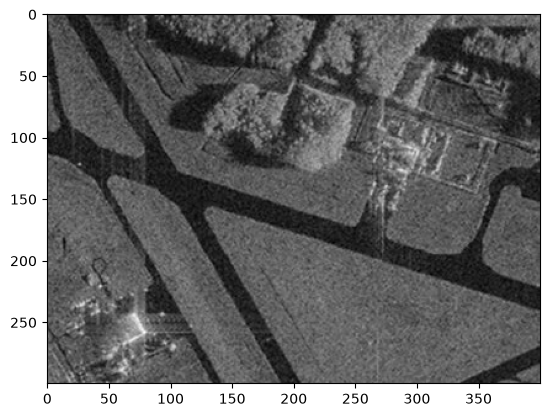

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap="gray")
plt.show()

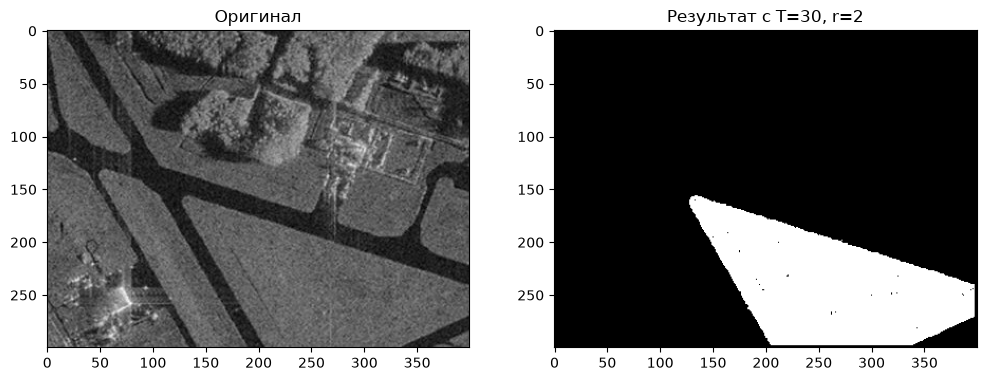

In [6]:
# 1
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
    if abs(av_val - img[point]) <= T:
        return True
    return False

def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i,j]==0 and mask[i-r:i+r, j-r:j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
    return mask*255

seed_point = (250, 250)
T_avg = 30 
r = 2
mask_avg = region_growing(image_gray, seed_point, homo_average, r, T_avg)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(image_gray, cmap="gray")
plt.title("Оригинал")
plt.subplot(1, 2, 2)
plt.imshow(mask_avg, cmap="gray")
plt.title(f"Результат с T={T_avg}, r={r}")
plt.show()

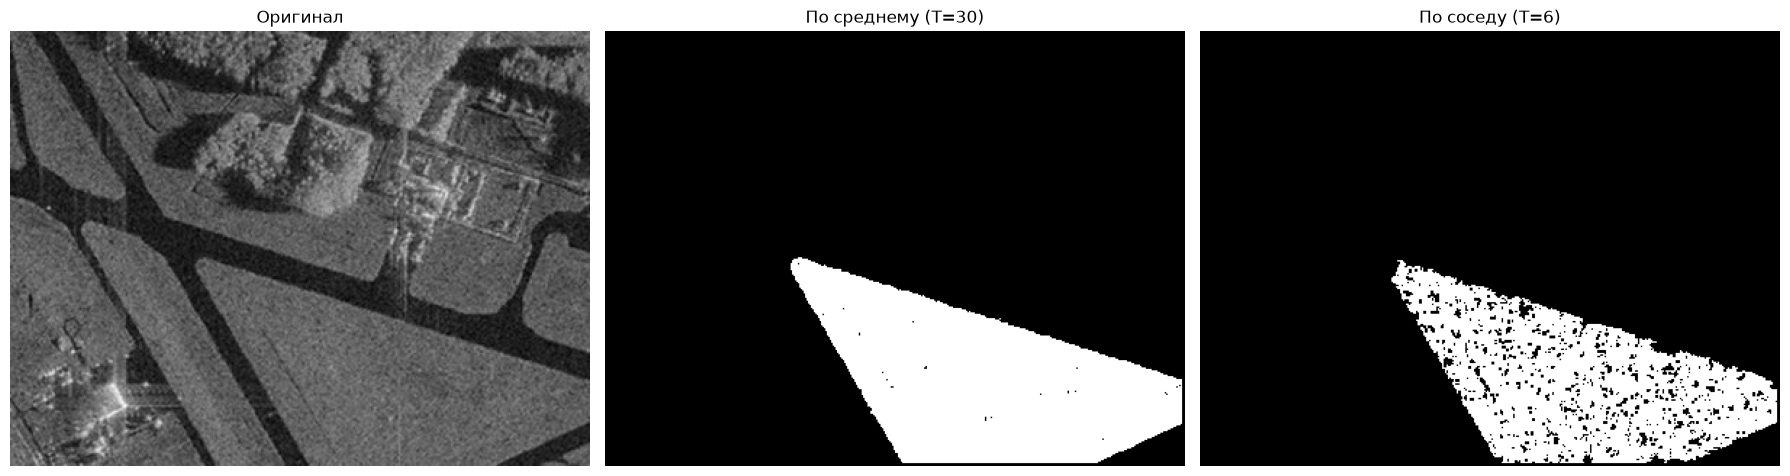


Пикселей в маске (по среднему): 21275
Пикселей в маске (по соседу):   17973


In [8]:
# 2
# по соседнему пикселю
def homo_neighbor(img, mask, point, T):
    i, j = point
    h, w = img.shape
    neighbors = []
    if i > 0    and mask[i-1, j] > 0: neighbors.append(img[i-1, j])
    if i < h-1  and mask[i+1, j] > 0: neighbors.append(img[i+1, j])
    if j > 0    and mask[i, j-1] > 0: neighbors.append(img[i, j-1])
    if j < w-1  and mask[i, j+1] > 0: neighbors.append(img[i, j+1])
    if not neighbors:
        return False
    return any(abs(int(img[i, j]) - int(nb)) <= T for nb in neighbors)

T_nb  = 6
mask_nb  = region_growing(image_gray, seed_point, homo_neighbor, r, T_nb)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(image_gray, cmap="gray"); axes[0].set_title("Оригинал")
axes[1].imshow(mask_avg, cmap="gray");   axes[1].set_title(f"По среднему (T={T_avg})")
axes[2].imshow(mask_nb,  cmap="gray");   axes[2].set_title(f"По соседу (T={T_nb})")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

print(f"\nПикселей в маске (по среднему): {np.count_nonzero(mask_avg)}")
print(f"Пикселей в маске (по соседу):   {np.count_nonzero(mask_nb)}")

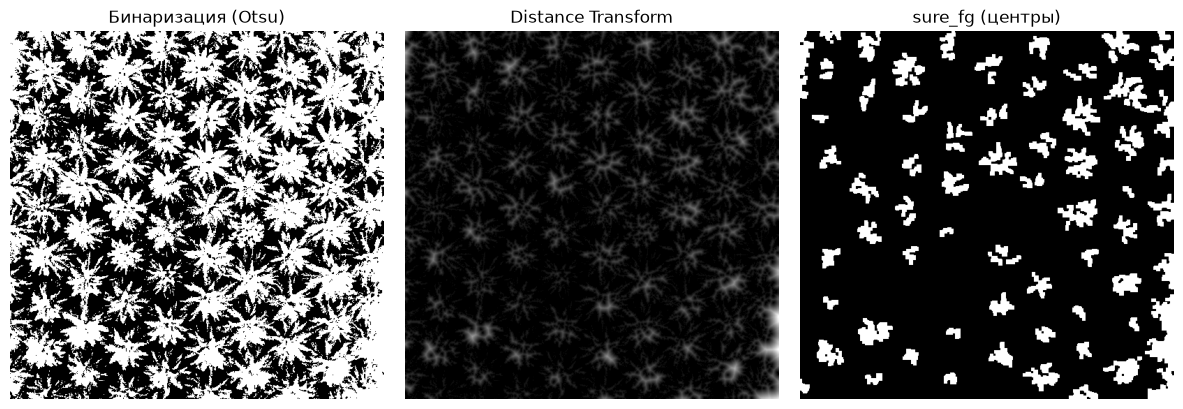

Найдено пальмовых деревьев: 81


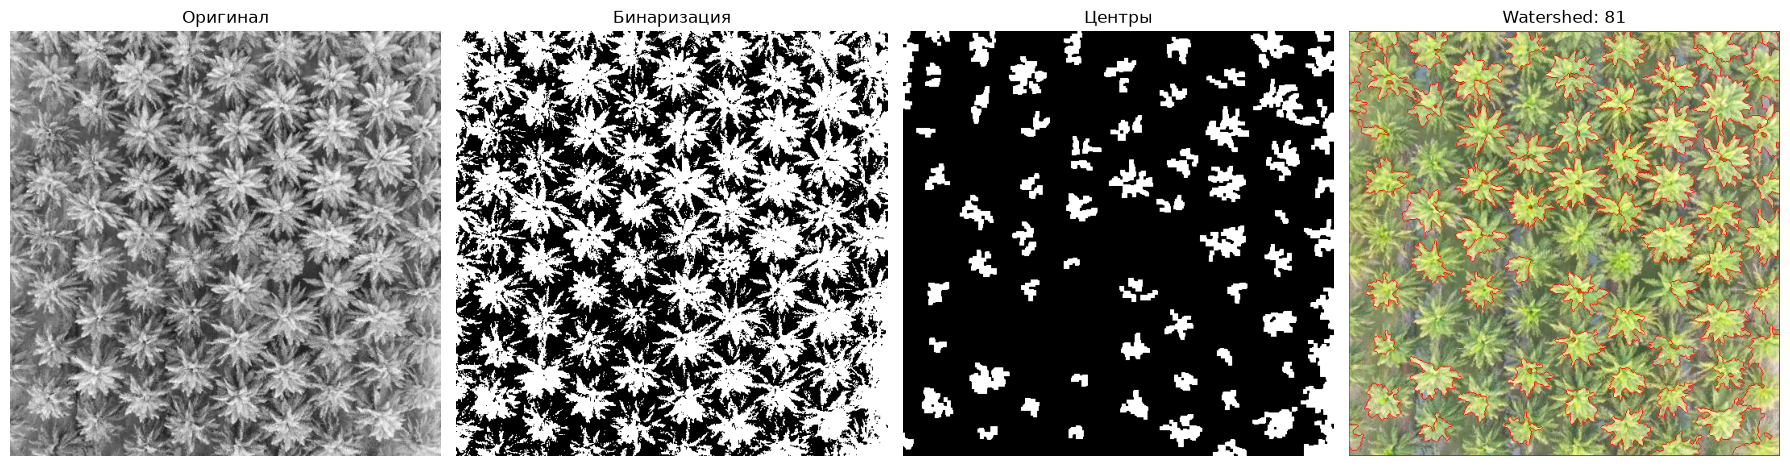

In [26]:
# 3
image = cv2.imread('palm_1.JPG')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

ret, thresh = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 

sure_fg = (dist > 0.1 * dist.max()).astype(np.uint8) * 255
sure_fg = cv2.morphologyEx(sure_fg, cv2.MORPH_OPEN, np.ones((3,3), np.uint8), iterations=2)
n, lbl, stats, _ = cv2.connectedComponentsWithStats(sure_fg, connectivity=8)
clean = np.zeros_like(sure_fg)
for i in range(1, n):
    if stats[i, cv2.CC_STAT_AREA] > 150:
        clean[lbl == i] = 255
sure_fg = clean

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(thresh, cmap="gray"); plt.title("Бинаризация (Otsu)")
plt.subplot(1, 3, 2); plt.imshow(dist,  cmap="gray"); plt.title("Distance Transform")
plt.subplot(1, 3, 3); plt.imshow(sure_fg, cmap="gray"); plt.title("sure_fg (центры)")
for a in plt.gcf().axes: a.axis("off")
plt.tight_layout(); plt.show()

_, markers = cv2.connectedComponents(sure_fg)
markers += 1
markers[cv2.dilate(thresh, np.ones((3,3), np.uint8)) - sure_fg == 255] = 0

markers = cv2.watershed(image, markers)

n_trees = len(set(np.unique(markers)) - {-1, 0, 1})
print(f"Найдено пальмовых деревьев: {n_trees}")

res = image.copy()
res[markers == -1] = [0, 0, 255]

fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, (img, title) in zip(ax, [(image_gray, "Оригинал"),
                                 (thresh, "Бинаризация"),
                                 (sure_fg, "Центры"),
                                 (cv2.cvtColor(res, cv2.COLOR_BGR2RGB), f"Watershed: {n_trees}")]):
    a.imshow(img, cmap="gray" if img.ndim == 2 else None)
    a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()